# Part 6 — Time-based mixture of experts
Paper §3.3 (Eq. 16), App. C.2–C.3. See [README.md](README.md).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline
from scoremd.moe import TimeMoE

## 1. Routing: which expert answers at which t?

In [2]:
moe = TimeMoE([models.EnergyNet(2, 64, 3), models.ScoreNet(2, 64, 2), models.ScoreNet(2, 54, 2)], [0.1, 0.6])
t = torch.tensor([1e-5, 0.05, 0.0999, 0.1, 0.3, 0.6, 0.99])
print(dict(zip(t.tolist(), moe.expert_index(t).tolist())))
print('parameters per expert:', [sum(p.numel() for p in e.parameters()) for e in moe.experts])

{1e-05: 0, 0.05: 0, 0.0999: 0, 0.1: 1, 0.3: 1, 0.6: 2, 0.99: 2}
parameters per expert: [10625, 6530, 4970]


## 2. Train Mixture and Both on Müller–Brown
Table 9 sizes: hidden `64, 64, 54`, layers `3, 2, 2`. Only expert 0 is energy-based; in **Both** only expert 0 gets
the FP loss. Experts are trained independently (could run in parallel).

loaded mb_diffusion_seed0.pt
-- expert 0: t in [1e-05, 0.1)  alpha=0.0
step   1000 | dsm 1.7205 | 7s
step   2000 | dsm 1.5511 | 12s
step   3000 | dsm 1.5493 | 18s
-- expert 1: t in [0.1, 0.6)  alpha=0.0
step    750 | dsm 0.7017 | 1s
-- expert 2: t in [0.6, 1.0)  alpha=0.0
step    750 | dsm 0.1253 | 2s
trained mb_mixture (seed 0) in 22s -> mb_mixture_seed0.pt
loaded mb_fp_seed0.pt
-- expert 0: t in [1e-05, 0.1)  alpha=0.15
step   1000 | dsm 1.9247 | fp 0.0860 | 39s
step   2000 | dsm 1.8213 | fp 0.1445 | 94s
step   3000 | dsm 1.7412 | fp 0.1744 | 128s
-- expert 1: t in [0.1, 0.6)  alpha=0.0
step    750 | dsm 0.7017 | 3s
-- expert 2: t in [0.6, 1.0)  alpha=0.0
step    750 | dsm 0.1253 | 4s
trained mb_both (seed 0) in 135s -> mb_both_seed0.pt
reference small-basin fraction 0.13691


,iid_pmf,sim_pmf,sim_basin
mb_diffusion,3.514867,5.878287,0.068000
mb_mixture,3.860139,2.684486,0.036611
mb_fp,11.614646,11.897209,0.153833
mb_both,5.555349,4.773897,0.061111


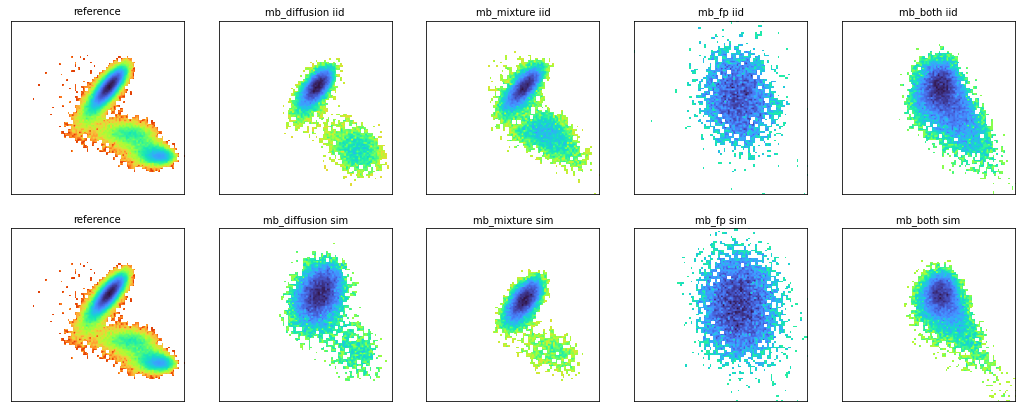

In [3]:
x, info = ex.load_system('mb'); rng = metrics.hist_range(x)
names = ['mb_diffusion', 'mb_mixture', 'mb_fp', 'mb_both']
res = {}
fig, ax = plt.subplots(2, 5, figsize=(18, 7))
plotting.free_energy_hist(ax[0, 0], x, rng, title='reference'); plotting.free_energy_hist(ax[1, 0], x, rng, title='reference')
for col, name in enumerate(names, start=1):
    m = ex.get_model(name)
    iid = ex.iid_samples(m); sim, _ = ex.simulate_model(m, x)
    plotting.free_energy_hist(ax[0, col], iid, rng, title=f'{name} iid'); plotting.free_energy_hist(ax[1, col], sim, rng, title=f'{name} sim')
    res[name] = dict(iid_pmf=ex.compare(iid, x)['pmf'], sim_pmf=ex.compare(sim, x)['pmf'],
                     sim_basin=ex.mb_small_basin_fraction(sim, info))
import pandas as pd
print('reference small-basin fraction', ex.mb_small_basin_fraction(x, info))
pd.DataFrame(res).T

## 3. Simulation only needs expert 0
For MD you can train *only* the `(0, 0.1)` expert — much cheaper than a full diffusion model. Here we confirm that the
force from the MoE at `t = 1e-5` is literally expert 0's force.

In [4]:
both = ex.get_model('mb_both')
tt = torch.full((5,), 1e-5)
print(torch.allclose(both.score(x[:5], tt), both.experts[0].score(x[:5], tt)))

loaded mb_both_seed0.pt
True


## Exercises
* App. C.2: compare against a single *wider* model with the same total parameter count (`ex.get_model('mb_diffusion', hidden=160)`).
* Move the first boundary to 0.05 or 0.2 (`ex.MOE_BOUNDS`) — the paper says results are robust if expert 0's interval is not too small.